<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorXGB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 42.4MB/s]


Dataset shape: (588, 9)

Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

Target distribution:
HPV_Label
0     58
1    530
Name: count, dtype: int64

Rows: 588
Train: 381
Validation: 89
Test: 118

Class counts (train):
HPV_Label
0     37
1    344
Name: count, dtype: int64

Class counts (validation):
HPV_Label
0     9
1    80
Name: count, dtype: int64

Class counts (test):
HPV_Label
0     12
1    106
Name: count, dtype: int64

Original predictors: 8
One-hot encoded features: 23
Training samples (no SMOTE): 381
Validation samples: 89
Test samples: 118

Automatic class weights: {0: 5.148648648648648, 1: 0.5537790697674418}
XGBoost scale_pos_weight: 0.10755813953488372
SMOTE: No

Validation balanced accuracy: 0.8201
Selected validation threshold: 0.590

VALIDATION METRICS:
Accuracy             0.853933
Balanced_Accuracy    0.820139
Precision            0.971831
Recall               0.862500
F1               

,Model,N_Train,N_Validation,N_Test,Original_Predictor_Count,Encoded_Feature_Count,N_Estimators,Learning_Rate,Scale_Pos_Weight,Validation_Accuracy,...,Validation_ROC_AUC,Validation_PR_AUC,Test_Accuracy,Test_Balanced_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_Threshold,Test_ROC_AUC,Test_PR_AUC
0,XGBoost,381,89,118,8,23,100,0.1,0.107558,0.853933,...,0.864583,0.982967,0.728814,0.590409,0.920455,0.764151,0.835052,0.59,0.706368,0.94611


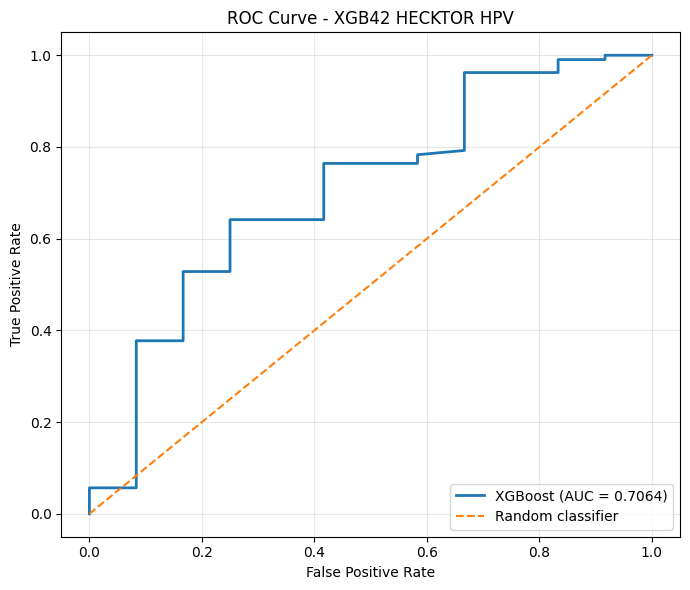

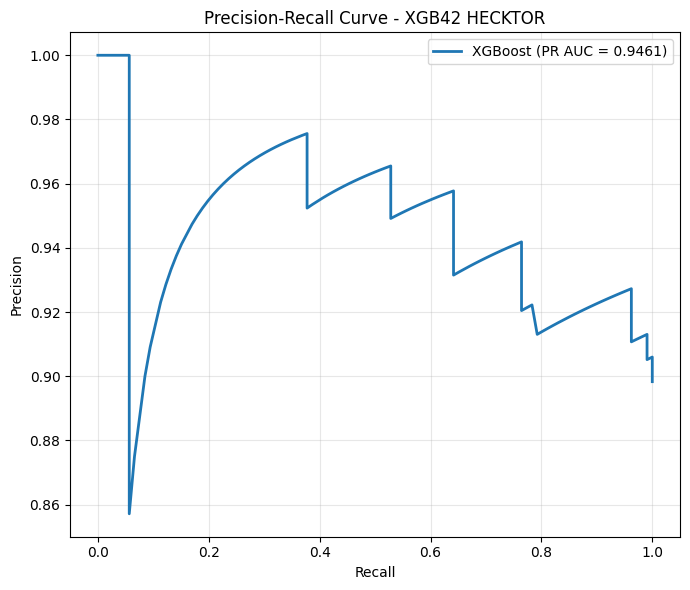


Feature importance (encoded predictors):
                feature  importance
             T-stage_T1    0.241827
             M-stage_M0    0.145705
             N-stage_N3    0.122134
             T-stage_T2    0.101594
             T-stage_T4    0.065638
             T-stage_T3    0.057822
             N-stage_N1    0.045133
Tobacco Consumption_0.0    0.044465
Alcohol Consumption_0.0    0.039926
                    Age    0.029332
             N-stage_N2    0.028409
 Performance Status_0.0    0.026615
 Performance Status_1.0    0.026531
               Gender_0    0.024869
               Gender_1    0.000000
Alcohol Consumption_1.0    0.000000
Tobacco Consumption_1.0    0.000000
 Performance Status_2.0    0.000000
 Performance Status_3.0    0.000000
 Performance Status_4.0    0.000000
             T-stage_T0    0.000000
             N-stage_N0    0.000000
             M-stage_M1    0.000000


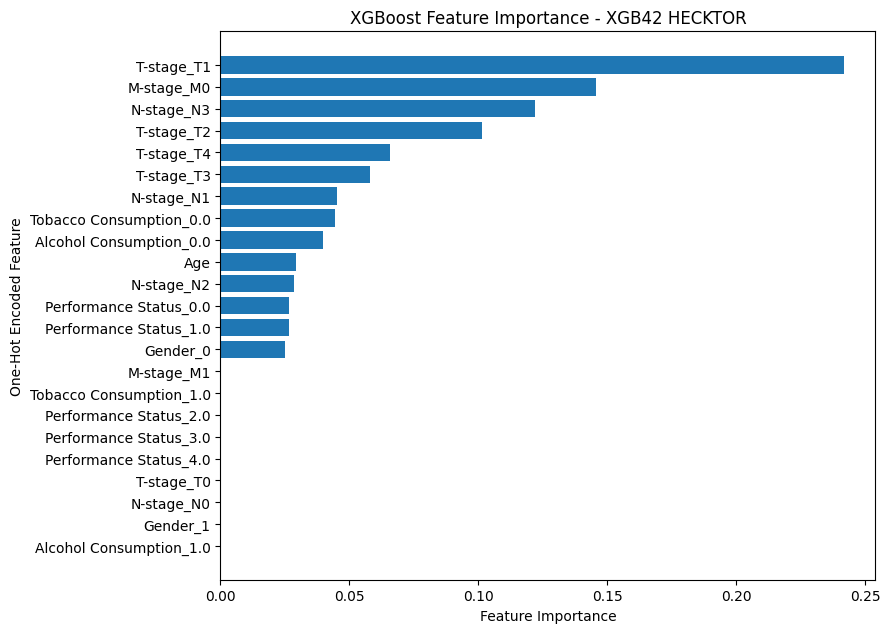


XGBOOST42_HECKTOR SUMMARY
Model: XGBoost
Original predictors: 8
One-hot encoded features: 23
Estimators: 100
Learning rate: 0.1
Scale_pos_weight: 0.10755813953488372
Random state: 42
Train / Validation / Test: 381 / 89 / 118
Split: Stratified 65 / 15 / 20
Excluded predictors: RFS, Relapse, Treatment
SMOTE: No
Class weighting: Training-only scale_pos_weight
Encoding: OneHotEncoder(handle_unknown='ignore')
Scaling: StandardScaler on Age only; fitted on training data
Threshold: Validation balanced accuracy over np.linspace(0.10, 0.90, 161)
Selected threshold: 0.590

Final test metrics:
Accuracy             0.728814
Balanced_Accuracy    0.590409
Precision            0.920455
Recall               0.764151
F1                   0.835052
Threshold            0.590000
ROC_AUC              0.706368
PR_AUC               0.946110
dtype: float64

Confusion matrix:
[[ 5  7]
 [25 81]]

Saved results folder: /content/drive/MyDrive/XGB_results_HECKTOR
Analysis complete.


In [1]:

# ============================================================
# XGB42_HECKTOR — XGBOOST HPV CLASSIFICATION
# Aligned with XGB42_HANCOCK workflow
# 8 predictors | Seed 42 | No SMOTE | No data leakage
# ============================================================

!pip install -q gdown xgboost

import os
import json
import random
import warnings
import joblib
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# 0. REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. LOAD AND PREPARE HECKTOR DATA
# ------------------------------------------------------------

gdown.download(
    id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
    output="HPV2025.xlsx",
    quiet=False
)

df = pd.read_excel("HPV2025.xlsx")

# Remove rows without an HPV outcome
df = df.dropna(subset=["HPV Status"]).copy()

# Remove identifiers and task columns if present
columns_to_drop = [
    "PatientID",
    "CenterID",
    "Task 1",
    "Task 2",
    "Task 3"
]

df = df.drop(
    columns=[c for c in columns_to_drop if c in df.columns],
    errors="ignore"
)

# ------------------------------------------------------------
# 2. NORMALISE THE TARGET LABEL
#    Positive = 1; Negative = 0
# ------------------------------------------------------------

def normalize_label(value):
    if pd.isna(value):
        return np.nan

    label = str(value).strip().lower()

    if label in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1

    if label in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0

    return np.nan


df["HPV_Label"] = df["HPV Status"].apply(normalize_label)

# Exclude rows with unrecognised target values
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

# ------------------------------------------------------------
# 3. DEFINE PREDICTORS
#    RFS, Relapse and Treatment are excluded.
# ------------------------------------------------------------

features = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

missing_columns = [c for c in features if c not in df.columns]

if missing_columns:
    raise KeyError(
        f"Missing required predictor columns: {missing_columns}"
    )

# Use only the specified predictors and target
model_df = df[features + ["HPV_Label"]].copy()

numeric_features = ["Age"]

# All other predictors, including tumour stages, are categorical
categorical_features = [
    c for c in features if c not in numeric_features
]

# Clean missing-value representations in categorical columns
missing_strings = {"", "nan", "none", "null", "na", "n/a"}

for col in categorical_features:
    def clean_category(value):
        if pd.isna(value):
            return np.nan

        value = str(value).strip()

        if value.lower() in missing_strings:
            return np.nan

        return value

    model_df[col] = model_df[col].apply(clean_category)

# Ensure Age is numeric
model_df["Age"] = pd.to_numeric(
    model_df["Age"],
    errors="coerce"
)

print("Dataset shape:", model_df.shape)
print("\nPredictors:", features)
print("\nTarget distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())

if model_df["HPV_Label"].nunique() != 2:
    raise ValueError(
        "The dataset must contain both HPV-negative (0) "
        "and HPV-positive (1) cases."
    )

# ------------------------------------------------------------
# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
#    65% / 15% / 20%, matching Hancock
# ------------------------------------------------------------

train_val, test = train_test_split(
    model_df,
    test_size=0.20,
    random_state=SEED,
    stratify=model_df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train = train.copy()
val = val.copy()
test = test.copy()

print("\nRows:", len(model_df))
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

print("\nClass counts (train):")
print(train["HPV_Label"].value_counts().sort_index())

print("\nClass counts (validation):")
print(val["HPV_Label"].value_counts().sort_index())

print("\nClass counts (test):")
print(test["HPV_Label"].value_counts().sort_index())

# ------------------------------------------------------------
# 5. PREPROCESSING — TRAINING DATA ONLY
#    Age: median imputation + StandardScaler
#    Categorical: mode imputation + OneHotEncoder
# ------------------------------------------------------------

try:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", onehot)
            ]),
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit preprocessing on training data only
X_train = preprocessor.fit_transform(train[features])
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])

y_train = train["HPV_Label"].to_numpy()
y_val = val["HPV_Label"].to_numpy()
y_test = test["HPV_Label"].to_numpy()

try:
    encoded_feature_names = (
        preprocessor.get_feature_names_out().tolist()
    )
except (AttributeError, TypeError):
    encoded_feature_names = [
        f"encoded_feature_{i}"
        for i in range(X_train.shape[1])
    ]

n_features = X_train.shape[1]

print("\nOriginal predictors:", len(features))
print("One-hot encoded features:", n_features)
print("Training samples (no SMOTE):", len(y_train))
print("Validation samples:", len(y_val))
print("Test samples:", len(y_test))

# ------------------------------------------------------------
# 6. CLASS IMBALANCE — TRAINING LABELS ONLY
#    XGBoost uses scale_pos_weight = negative / positive
# ------------------------------------------------------------

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both HPV classes must be present in the training set."
    )

class_weights = {
    i: float(len(y_train) / (2 * counts[i]))
    for i in range(2)
}

scale_pos_weight = float(counts[0] / counts[1])

print("\nAutomatic class weights:", class_weights)
print("XGBoost scale_pos_weight:", scale_pos_weight)
print("SMOTE: No")

# ------------------------------------------------------------
# 7. TRAIN XGBOOST
#    Same main parameters as Hancock XGBoost
# ------------------------------------------------------------

model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=SEED,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

# ------------------------------------------------------------
# 8. SELECT THRESHOLD USING VALIDATION SET ONLY
#    161 thresholds from 0.10 to 0.90
#    Maximise balanced accuracy
#    Ties resolved by threshold closest to 0.50
# ------------------------------------------------------------

val_prob = model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.10, 0.90, 161)

threshold_scores = [
    balanced_accuracy_score(
        y_val,
        (val_prob >= threshold).astype(int)
    )
    for threshold in thresholds
]

best_score = max(threshold_scores)

best_threshold = float(
    min(
        (
            threshold
            for threshold, score in zip(
                thresholds, threshold_scores
            )
            if score == best_score
        ),
        key=lambda threshold: abs(threshold - 0.5)
    )
)

print(f"\nValidation balanced accuracy: {best_score:.4f}")
print(f"Selected validation threshold: {best_threshold:.3f}")

# ------------------------------------------------------------
# 9. METRIC CALCULATION
# ------------------------------------------------------------

def calculate_metrics(y_true, probabilities, predictions, threshold):
    both_classes = len(np.unique(y_true)) == 2

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Threshold": float(threshold),
        "ROC_AUC": (
            roc_auc_score(y_true, probabilities)
            if both_classes else np.nan
        ),
        "PR_AUC": (
            average_precision_score(y_true, probabilities)
            if both_classes else np.nan
        )
    }


val_pred = (val_prob >= best_threshold).astype(int)

val_metrics = calculate_metrics(
    y_val,
    val_prob,
    val_pred,
    best_threshold
)

print("\nVALIDATION METRICS:")
print(pd.Series(val_metrics))

# ------------------------------------------------------------
# 10. FINAL TEST EVALUATION
#     Test set is not used for threshold selection
# ------------------------------------------------------------

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

test_metrics = calculate_metrics(
    y_test,
    test_prob,
    test_pred,
    best_threshold
)

print("\nTEST METRICS:")
print(pd.Series(test_metrics))

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

print("\nConfusion matrix:\n", cm)

print(
    "\nClassification report:\n",
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 11. SAVE RESULTS — HECKTOR OUTPUT DIRECTORY
# ------------------------------------------------------------

OUT_DIR = "/content/drive/MyDrive/XGB_results_HECKTOR"
os.makedirs(OUT_DIR, exist_ok=True)

results_df = pd.DataFrame([{
    "Model": "XGBoost",
    "N_Train": len(y_train),
    "N_Validation": len(y_val),
    "N_Test": len(y_test),
    "Original_Predictor_Count": len(features),
    "Encoded_Feature_Count": int(n_features),
    "N_Estimators": model.n_estimators,
    "Learning_Rate": model.learning_rate,
    "Scale_Pos_Weight": scale_pos_weight,
    **{
        f"Validation_{key}": value
        for key, value in val_metrics.items()
    },
    **{
        f"Test_{key}": value
        for key, value in test_metrics.items()
    }
}])

results_path = os.path.join(OUT_DIR, "metrics.csv")
results_df.to_csv(results_path, index=False)

predictions_df = pd.DataFrame({
    "y_true": y_test,
    "probability_positive": test_prob,
    "prediction": test_pred
})

predictions_path = os.path.join(
    OUT_DIR, "test_predictions.csv"
)
predictions_df.to_csv(predictions_path, index=False)

settings = {
    "model": "XGBClassifier",
    "dataset": "HPV2025.xlsx",
    "seed": SEED,
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target_column": "HPV Status",
    "target_mapping": {
        "positive": 1,
        "pos": 1,
        "1": 1,
        "1.0": 1,
        "true": 1,
        "yes": 1,
        "negative": 0,
        "neg": 0,
        "0": 0,
        "0.0": 0,
        "false": 0,
        "no": 0
    },
    "excluded_predictors": ["RFS", "Relapse", "Treatment"],
    "threshold": best_threshold,
    "validation_balanced_accuracy": float(best_score),
    "scale_pos_weight": scale_pos_weight,
    "class_weights": class_weights,
    "smote": False,
    "split": {
        "train_fraction_approx": 0.65,
        "validation_fraction_approx": 0.15,
        "test_fraction": 0.20,
        "stratified": True,
        "random_state": SEED,
        "train_n": len(train),
        "validation_n": len(val),
        "test_n": len(test)
    },
    "model_parameters": {
        "n_estimators": 100,
        "learning_rate": 0.1,
        "eval_metric": "logloss"
    },
    "preprocessing": {
        "numeric": (
            "Median imputation then StandardScaler; "
            "fit on training data only"
        ),
        "categorical": (
            "Most-frequent imputation then OneHotEncoder "
            "with handle_unknown='ignore'; "
            "fit on training data only"
        )
    },
    "encoded_feature_names": encoded_feature_names
}

with open(
    os.path.join(OUT_DIR, "settings.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(settings, f, indent=2)

joblib.dump(
    {
        "model": model,
        "preprocessor": preprocessor,
        "features": features,
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "target_column": "HPV Status",
        "threshold": best_threshold,
        "encoded_feature_names": encoded_feature_names
    },
    os.path.join(OUT_DIR, "XGB42_HECKTOR_model.joblib")
)

print("\nSaved metrics to:", results_path)
print("Saved test predictions to:", predictions_path)

print("\nTest results:")
display(results_df)

# ------------------------------------------------------------
# 12. ROC / AUC CURVE
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(y_test, test_prob)
auc_curve = roc_auc_score(y_test, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {auc_curve:.4f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGB42 HECKTOR HPV")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 13. PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    test_prob
)

pr_auc_curve = average_precision_score(y_test, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    recall_values,
    precision_values,
    linewidth=2,
    label=f"XGBoost (PR AUC = {pr_auc_curve:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGB42 HECKTOR")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "precision_recall_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 14. XGBOOST FEATURE IMPORTANCE
#     Importance is reported for encoded features
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "feature": encoded_feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance.to_csv(
    os.path.join(OUT_DIR, "feature_importance.csv"),
    index=False
)

print("\nFeature importance (encoded predictors):")
print(feature_importance.to_string(index=False))

top_n = min(25, len(feature_importance))

plot_importance = (
    feature_importance.head(top_n)
    .sort_values("importance")
)

plt.figure(figsize=(9, max(5, 0.28 * top_n)))
plt.barh(
    plot_importance["feature"],
    plot_importance["importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("One-Hot Encoded Feature")
plt.title("XGBoost Feature Importance - XGB42 HECKTOR")
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 15. MODEL SUMMARY
# ------------------------------------------------------------

print("\n====================================")
print("XGBOOST42_HECKTOR SUMMARY")
print("====================================")
print("Model: XGBoost")
print("Original predictors:", len(features))
print("One-hot encoded features:", n_features)
print("Estimators:", model.n_estimators)
print("Learning rate:", model.learning_rate)
print("Scale_pos_weight:", scale_pos_weight)
print("Random state:", SEED)
print(
    "Train / Validation / Test:",
    f"{len(train)} / {len(val)} / {len(test)}"
)
print("Split: Stratified 65 / 15 / 20")
print("Excluded predictors: RFS, Relapse, Treatment")
print("SMOTE: No")
print("Class weighting: Training-only scale_pos_weight")
print("Encoding: OneHotEncoder(handle_unknown='ignore')")
print("Scaling: StandardScaler on Age only; fitted on training data")
print(
    "Threshold: Validation balanced accuracy over "
    "np.linspace(0.10, 0.90, 161)"
)
print("Selected threshold:", f"{best_threshold:.3f}")

print("\nFinal test metrics:")
print(pd.Series(test_metrics))

print("\nConfusion matrix:")
print(cm)

print("\nSaved results folder:", OUT_DIR)
print("Analysis complete.")
